# 01 – Data exploration: UCI SMS Spam Collection

**Goal:** understand the data before modelling: size, class balance, duplicates, message length, and the signals that separate spam from normal messages (ham).

**Source:** [ucirvine/sms_spam](https://huggingface.co/datasets/ucirvine/sms_spam) (Almeida, Gómez Hidalgo & Yamakami, 2011).

In [1]:
import re, html
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option("display.max_colwidth", 120)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent   # works from the repo root or from notebooks/

## 1. Load the data
From Hugging Face if available, otherwise from a local copy in `data/raw/`.

In [2]:
try:
    from datasets import load_dataset
    ds = load_dataset("ucirvine/sms_spam", split="train")
    df = ds.to_pandas().rename(columns={"sms": "text"})
    df["label"] = df["label"].map({0: "ham", 1: "spam"})
except Exception as e:
    print("Hugging Face not reachable, using local copy:", type(e).__name__)
    df = pd.read_csv(ROOT / "data/raw/sms.tsv", sep="\t", header=None, names=["label", "text"])

df["text"] = df["text"].astype(str).str.strip()
print(df.shape)
df.head()

README.md:   0%|          | 0.00/4.98k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  359kB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5574 [00:00<?, ? examples/s]

(5574, 2)


,text,label
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives around here though",ham


## 2. Class balance

       count  share %
label                
ham     4827     86.6
spam     747     13.4


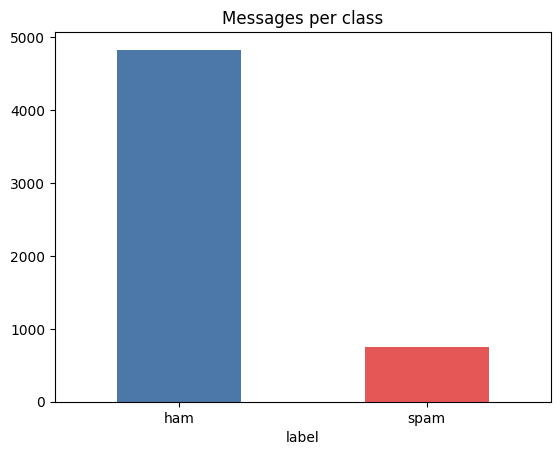

In [3]:
counts = df["label"].value_counts()
print(pd.DataFrame({"count": counts, "share %": (counts / len(df) * 100).round(1)}))
counts.plot.bar(color=["#4C78A8", "#E45756"], title="Messages per class", rot=0); plt.show()

**Reading:** the data is imbalanced (about 13% spam). A model that always answers "ham" already gets ~87% accuracy, so **accuracy alone is misleading**. We will report precision, recall and F1 on the spam class.

## 3. Duplicates and empty messages

In [4]:
dup = df.duplicated("text")
print("Empty messages:", (df["text"] == "").sum())
print("Duplicate texts:", dup.sum(), f"({dup.mean():.1%})")
print(df[dup]["label"].value_counts())
df[dup]["text"].value_counts().head(8)

Empty messages: 0
Duplicate texts: 414 (7.4%)
label
ham     309
spam    105
Name: count, dtype: int64


,count
text,
"Sorry, I'll call later",29
I cant pick the phone right now. Pls send a message,11
Ok...,9
Ok,3
"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.",3
Okie,3
"7 wonders in My WORLD 7th You 6th Ur style 5th Ur smile 4th Ur Personality 3rd Ur Nature 2nd Ur SMS and 1st ""Ur Lovely Friendship""... good morning dear",3
Ok.,3


**Why it matters:** if the same message appears in both the training and the test set, the model is tested on messages it has already seen, and the score is inflated. We remove duplicates **before** splitting.

## 4. Encoding artifacts
The top ham words include `gt` and `lt`: they come from HTML codes (`&lt;`, `&gt;`, `&amp;`) left in the text, and `&lt;#&gt;` is a placeholder that replaced numbers when the messages were anonymised.

In [5]:
art = df["text"].str.contains("&lt;|&gt;|&amp;")
print(df[art]["label"].value_counts())
df[art]["text"].head(4)

label
ham    309
Name: count, dtype: int64


,text
28,"I'm back &amp; we're packing the car now, I'll let you know if there's room"
44,Great! I hope you like your man well endowed. I am &lt;#&gt; inches...
51,"A gram usually runs like &lt;#&gt; , a half eighth is smarter though and gets you almost a whole second gram for &..."
55,Do you know what Mallika Sherawat did yesterday? Find out now @ &lt;URL&gt;


**This is a leak:** these codes appear **only in ham**. A model would learn "contains `lt`/`gt` = not spam", a rule that means nothing in real life. We decode the HTML codes and remove the `<#>` placeholder in the cleaning step.

## 5. Message length

label             ham   spam
n_chars count  4827.0  747.0
        mean     71.0  139.0
        std      58.0   29.0
        min       2.0   13.0
        25%      33.0  133.0
        50%      52.0  149.0
        75%      93.0  157.0
        max     910.0  223.0
n_words count  4827.0  747.0
        mean     14.0   24.0
        std      12.0    6.0
        min       1.0    2.0
        25%       7.0   22.0
        50%      11.0   25.0
        75%      19.0   28.0
        max     171.0   35.0


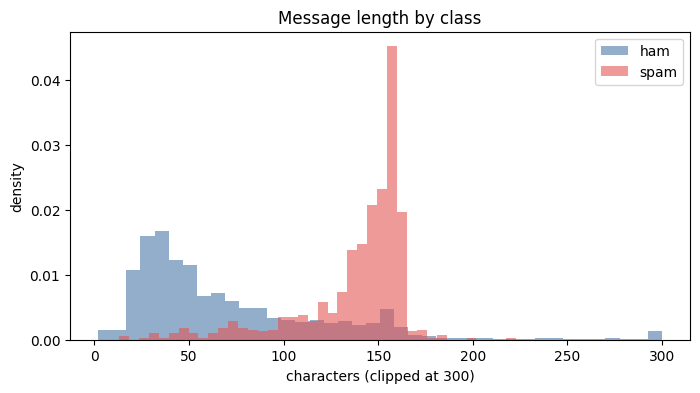

In [6]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()
print(df.groupby("label")[["n_chars", "n_words"]].describe().round(0).T)

fig, ax = plt.subplots(figsize=(8, 4))
for lab, color in [("ham", "#4C78A8"), ("spam", "#E45756")]:
    ax.hist(df.loc[df.label == lab, "n_chars"].clip(upper=300), bins=40, alpha=.6, label=lab, color=color, density=True)
ax.set(xlabel="characters (clipped at 300)", ylabel="density", title="Message length by class"); ax.legend(); plt.show()

## 6. Surface signals
Simple patterns that scammers use: links, long phone numbers, money symbols, capital letters.

In [7]:
signals = {
    "has_url":      r"https?://|www\.|\.(?:com|co\.uk|net)\b",
    "has_phone_5+": r"\d{5,}",
    "has_money":    r"[£$€]|\bcash\b|\bprize\b",
    "has_free_win": r"\b(free|win|won|winner|claim|urgent)\b",
}
for name, pat in signals.items():
    df[name] = df["text"].str.contains(pat, case=False, regex=True)
df["upper_ratio"] = df["text"].apply(lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t)))

(df.groupby("label")[list(signals) + ["upper_ratio"]].mean() * 100).round(1).T.rename(columns=lambda c: c + " %")

/tmp/ipykernel_2502/3635001841.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[name] = df["text"].str.contains(pat, case=False, regex=True)


label,ham %,spam %
has_url,0.3,18.5
has_phone_5+,0.1,78.3
has_money,0.6,37.6
has_free_win,1.9,49.9
upper_ratio,7.9,16.7


## 7. Most frequent words per class

In [8]:
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
    X = cv.fit_transform(texts)
    freq = pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out())
    return freq.sort_values(ascending=False).head(n)

pd.concat({"ham": top_words(df[df.label == "ham"].text).reset_index(),
           "spam": top_words(df[df.label == "spam"].text).reset_index()}, axis=1)

ham         spam     
    index    0   index    0
0      gt  318    free  224
1      lt  316     txt  163
2    just  297      ur  144
3      ok  288  mobile  127
4      ll  266    text  125
5      ur  247    stop  123
6    know  237   claim  113
7    good  235   reply  104
8    like  234     www   98
9     got  233   prize   93
10   come  230    just   79
11    day  212     won   76
12   love  205    cash   76
13   time  202      uk   74
14  going  169    send   71

## 8. Examples

In [9]:
df[df.label == "spam"].sample(8, random_state=0)[["text"]]

,text
1848,"FREE NOKIA Or Motorola with upto 12mths 1/2price linerental, 500 FREE x-net mins&100txt/mth FREE B'tooth*. Call Mobi..."
3913,You have an important customer service announcement. Call FREEPHONE 0800 542 0825 now!
68,"Did you hear about the new ""Divorce Barbie""? It comes with all of Ken's stuff!"
188,Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaran...
3801,We tried to contact you re your reply to our offer of a Video Handset? 750 anytime any networks mins? UNLIMITED TEXT...
541,from www.Applausestore.com MonthlySubscription@50p/msg max6/month T&CsC web age16 2stop txt stop
2804,FreeMsg>FAV XMAS TONES!Reply REAL
525,"URGENT!: Your Mobile No. was awarded a £2,000 Bonus Caller Prize on 02/09/03! This is our 2nd attempt to contact YOU..."


In [10]:
df[df.label == "ham"].sample(8, random_state=0)[["text"]]

,text
5515,Yes. Please leave at &lt;#&gt; . So that at &lt;#&gt; we can leave
2192,Thankyou so much for the call. I appreciate your care.
4447,Merry christmas to u too annie!
5392,Nt joking seriously i told
5001,Well its not like you actually called someone a punto. That woulda been worse.
185,Going on nothing great.bye
4109,Pls send me your address sir.
52,K fyi x has a ride early tomorrow morning but he's crashing at our place tonight


## 9. What we learned, and the limits of this data

- **Small and imbalanced:** ~5.5k messages, ~13% spam. We use precision / recall / F1 on spam, and a stratified split.
- **414 duplicates (7.4%)**: 309 ham (short replies like "Sorry, I'll call later") and 105 spam (14% of all spam, the same campaign sent several times). They are removed before the train/test split, otherwise the model is tested on messages it has already seen.
- **Encoding leak:** 309 ham messages contain HTML codes (`&lt;#&gt;`) that never appear in spam. We clean them so the model cannot use them as a shortcut.
- **Spam is longer** (median 149 characters vs 52) and full of phone numbers (78% of spam vs 0.1% of ham), money and words like *free / txt / claim / prize*. Only 18% of spam contains a link. A simple model will find these signals easily, so **we expect a very high score**.
- **Biases and limits:**
  - **Old:** messages collected around 2010–2012, mostly UK premium-rate spam ("text WIN to 80086"). Modern scams (fake parcel delivery, bank, tax, fines, with a link) are almost absent.
  - **Language and place:** English only; the ham comes largely from Singaporean students (NUS SMS corpus), with its own slang ("lar", "wat", "ur").
  - **Spam ≠ scam:** many "spam" messages are annoying marketing (ringtones, phone deals), not fraud.
  - **Some label noise:** e.g. a "Divorce Barbie" joke is labelled spam. We will look for such cases in the error analysis.
- **Consequence for the project:** a high test score here does **not** prove the model detects today's scams. We therefore add a second test set of real recent scam SMS collected by the team (in French and English), and compare approaches on it.

## 10. Save the clean dataset

In [11]:
def clean_text(t):
    t = html.unescape(t).replace("<#>", " ")      # decode &lt; &gt; &amp; and drop the anonymisation placeholder
    return re.sub(r"\s+", " ", t).strip()

df["text"] = df["text"].apply(clean_text)
clean = df[df["text"] != ""].drop_duplicates("text")[["text", "label"]].reset_index(drop=True)
clean.to_csv(ROOT / "data/sms_clean.csv", index=False)
print(clean.shape)
print(clean["label"].value_counts())

OSError: Cannot save file into a non-existent directory: '/data'